# 02 – Baseline linear regression
**Goal:** fit the baseline model and measure it on vehicles it has never seen.
Under each result, write what you see and what it means in your own words.

In [18]:
import sys; sys.path.insert(0, "../src")
import pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from ev_energy import (load_data, clean_data, split_by_vehicle, evaluate,
                       TARGET, TRIP_FEATURES, ELECTRICAL_FEATURES)

df = clean_data(load_data("../data/raw/ev_trip_energy.csv"))
print("trips after cleaning:", len(df))

trips after cleaning: 10150


## 1. Split by vehicle
Whole vehicles are held out, so the test set measures performance on cars the model has not seen.
(A random split by trip would let the same car appear in both sets and flatter the score.)

In [19]:
train, test = split_by_vehicle(df, test_size=0.2, seed=42)
print("train trips:", len(train), "| test trips:", len(test))
print("vehicles in train:", train.vehicle_id.nunique(), "| in test:", test.vehicle_id.nunique())

train trips: 7958 | test trips: 2192
vehicles in train: 40 | in test: 10


## 2. Fit the baseline with two feature sets

In [20]:
feature_sets = {"trip only": TRIP_FEATURES,
                "trip + electrical": TRIP_FEATURES + ELECTRICAL_FEATURES}
rows, preds = [], {}
for name, feats in feature_sets.items():
    model = LinearRegression().fit(train[feats], train[TARGET])
    preds[name] = model.predict(test[feats])
    rows.append({"features": name, **evaluate(test[TARGET], preds[name])})
results = pd.DataFrame(rows).set_index("features").round(3)
results

,MAE,RMSE,R2
features,,,
trip only,0.812,1.204,0.841
trip + electrical,0.785,1.164,0.851



>
> **Baseline results (seed 42, 10 unseen test vehicles).**
> | Features | MAE (kWh) | RMSE (kWh) | R² |
> |---|---|---|---|
> | Trip only | 0.812 | 1.204 | 0.841 |
> | Trip + electrical | 0.785 | 1.164 | 0.851 |
>
> Adding current and voltage improves things only slightly: MAE falls by about 0.03 kWh (3%) and R² rises by 0.01. Across 10 different vehicle splits the electrical version won every time, so the gain is small but consistent.
> For scale: the average trip uses 3.95 kWh, so an MAE of 0.8 kWh is about a 20% typical error (or about 3.6% of the 22.4 kWh pack). RMSE is larger than MAE, which means a few trips have much bigger errors than the typical one.
> A fixed rate of about 0.21 kWh/km times distance scores R² of 0.82 on the same split, so linear regression only modestly improves on it. Distance does most of the work.
> Caveat: current and voltage are measured during the trip, so the second row is an upper bound for a prediction made before a journey.

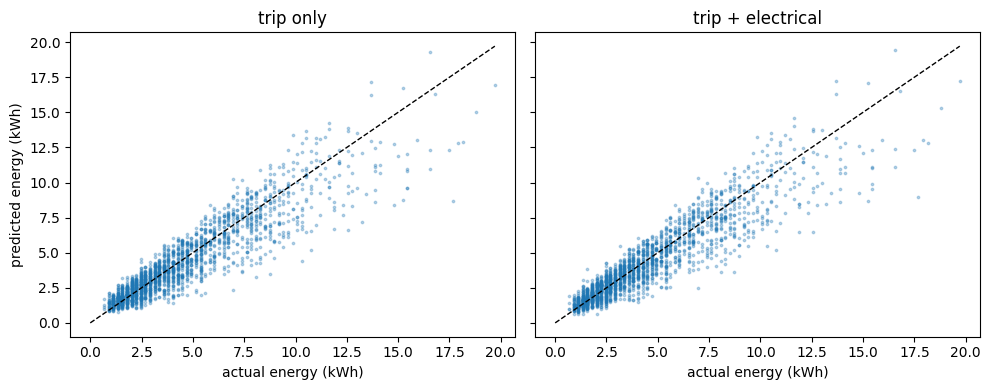

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(test[TARGET], p, s=3, alpha=.3)
    lim = [0, test[TARGET].max()]
    a.plot(lim, lim, "k--", lw=1)
    a.set(xlabel="actual energy (kWh)", title=name)
ax[0].set_ylabel("predicted energy (kWh)")
plt.tight_layout(); plt.savefig("../figures/baseline_pred_vs_actual.png", dpi=150); plt.show()


>
> **Predicted vs actual.** The predicted scatters a bit more for higher energy for trip only. Larger errors on long trips. the scatter widens for high-energy trips (larger errors on long trips); horizontal bands caused by the 0.224 kWh steps in the target; high energy trips are systematically under predicted (points below the diagonal at the top right).